# Artificial Intelligence


* Md. Jalil Piran
* Sejong University
* piran@sejong.ac.kr


# K-means Clustering — Iris Flowers


## Discover groups using petal measurements
- **Goal:** group flowers with similar petal measurements without giving the algorithm their species.
- **Data:** the real Iris dataset, downloaded directly from an online CSV: 150 flowers, four measurements in centimeters, and a species column kept only for later interpretation.
- **Beginner scope:** use only **petal length and petal width** so every input dimension can be shown in a scatter plot. Four-feature clustering is an optional extension.
- **Environment:** Python 3 with pandas, NumPy, Matplotlib, seaborn, scikit-learn, joblib, and IPython. No GPU, Google Drive mount, or manual CSV download is required.
- **Setup if needed:** run `%pip install pandas numpy matplotlib seaborn scikit-learn joblib ipython`, restart the kernel, then run this notebook from top to bottom.
- **Internet:** required for the default loading cell. An optional local CSV path is provided if you have downloaded the same file.
- **Lesson route:** load → inspect → select features → understand distance and centroids → scale → compare K → fit → interpret → assign new flowers → save/reload.

**Dataset:** [Online Iris CSV](https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv), hosted in the [seaborn example-data repository](https://github.com/mwaskom/seaborn-data). This is an existing dataset, not synthetic data.


| Concept | This clustering lesson |
|---|---|
| Observations | Individual flowers |
| Input features | Petal length and petal width |
| Training target | None; species is excluded |
| Model | K centroid locations |
| Objective | Minimize within-cluster squared distances |
| Output | Cluster ID and distances to centroids |
| Internal evaluation | Inertia and silhouette |
| Optional reference evaluation | Compare the frozen groups with species using ARI |


### 1. Import libraries

- Import tools once and apply a consistent display style.
- `KMeans` performs clustering; `StandardScaler` prepares the distance representation.


In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (8, 4), "figure.dpi": 110})
pd.set_option("display.precision", 4)
print("scikit-learn:", sklearn.__version__)


scikit-learn: 1.4.2


- This lesson uses ordinary CPU-based clustering and a small dataset suitable for a classroom demonstration.


### 2. Configure the experiment

- Put data-source and model settings together so students can find them easily.
- `N_INIT=10` tries ten initializations and keeps the one with the lowest inertia.
- The main K-selection rule will use silhouette, without consulting species.


In [2]:
RANDOM_STATE = 42
DATA_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
LOCAL_DATA_PATH = None  # Optional: Path("iris.csv"); None reads the online CSV.
ALL_FEATURES = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
FEATURES = ["petal_length", "petal_width"]
K_VALUES = range(1, 9)
N_INIT = 10
MAX_ITER = 300
ARTIFACT_DIR = Path("iris_kmeans_artifacts")

def make_model(k):
    return KMeans(n_clusters=k, init="k-means++", n_init=N_INIT,
                  max_iter=MAX_ITER, random_state=RANDOM_STATE)


**Hyperparameters:**
- K sets the number of groups.
- `n_init` controls independent initializations; `max_iter` limits iterations per initialization.
- A fixed `random_state` makes repeated classroom runs reproducible in the same software environment.


### 3. Load the dataset from the internet

- Read the CSV URL directly with pandas; no account or login is needed.
- If you prefer a local copy, set `LOCAL_DATA_PATH` above.
- A loading failure should be visible rather than silently switching to a different dataset.


In [3]:
if LOCAL_DATA_PATH is None:
    raw_df = pd.read_csv(DATA_URL)
    data_source = DATA_URL
else:
    csv_path = Path(LOCAL_DATA_PATH).expanduser()
    if not csv_path.is_file():
        raise FileNotFoundError(f"Cannot find {csv_path.resolve()}")
    raw_df = pd.read_csv(csv_path)
    data_source = str(csv_path.resolve())
print("Source:", data_source)
print("Rows and columns:", raw_df.shape)
display(raw_df.head())


Source: https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv
Rows and columns: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


- Each row describes one flower. The four measurements are features; `species` is a reference label that will not be used to train K-means.


### 4. Check data types and missing values

- Keep the original table and validate a copy.
- Require finite, positive measurements in centimeters.
- Report exact duplicates without automatically removing flowers that happen to share measurements.


In [4]:
df = raw_df.copy()
required = ALL_FEATURES + ["species"]
if not df.columns.is_unique:
    raise ValueError("Duplicate column names.")
if not set(required).issubset(df.columns):
    raise ValueError(f"Expected columns: {required}")
df = df[required].copy()
for column in ALL_FEATURES:
    df[column] = pd.to_numeric(df[column], errors="raise").astype(float)
if not np.isfinite(df[ALL_FEATURES].to_numpy()).all():
    raise ValueError("Missing or infinite measurements; inspect the input data.")
if (df[ALL_FEATURES] <= 0).any().any():
    raise ValueError("Flower measurements must be positive.")
if df["species"].isna().any():
    raise ValueError("Missing reference species labels.")
df.info()
display(df.isna().sum().to_frame("Missing values"))
print("Exact repeated rows:", df.duplicated().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


,Missing values
sepal_length,0
sepal_width,0
petal_length,0
petal_width,0
species,0


Exact repeated rows: 1


- The online Iris table is complete. For another dataset, missing values need an explicit treatment before K-means can be fitted.


### 5. Choose two features and summarize them

- Use petal measurements to keep the main lesson two-dimensional.
- Store species separately. Do not encode it and append it to the feature matrix.
- Inspect the feature ranges, averages, and spread.


In [5]:
X = df[FEATURES].copy()
species_reference = df["species"].copy()
assert "species" not in X.columns
print("Clustering features:", list(X.columns))
print("Feature matrix shape:", X.shape)
display(X.describe())


Clustering features: ['petal_length', 'petal_width']
Feature matrix shape: (150, 2)


,petal_length,petal_width
count,150.0000,150.0000
mean,3.7580,1.1993
std,1.7653,0.7622
min,1.0000,0.1000
25%,1.6000,0.3000
50%,4.3500,1.3000
75%,5.1000,1.8000
max,6.9000,2.5000


- A petal is an inner flower part. Length and width are related measurements; two similar flowers may still belong to different species.


### 6. Explore the unlabeled measurements

- Plot the observed features without species colors.
- Look for compact groups and overlap before selecting K.


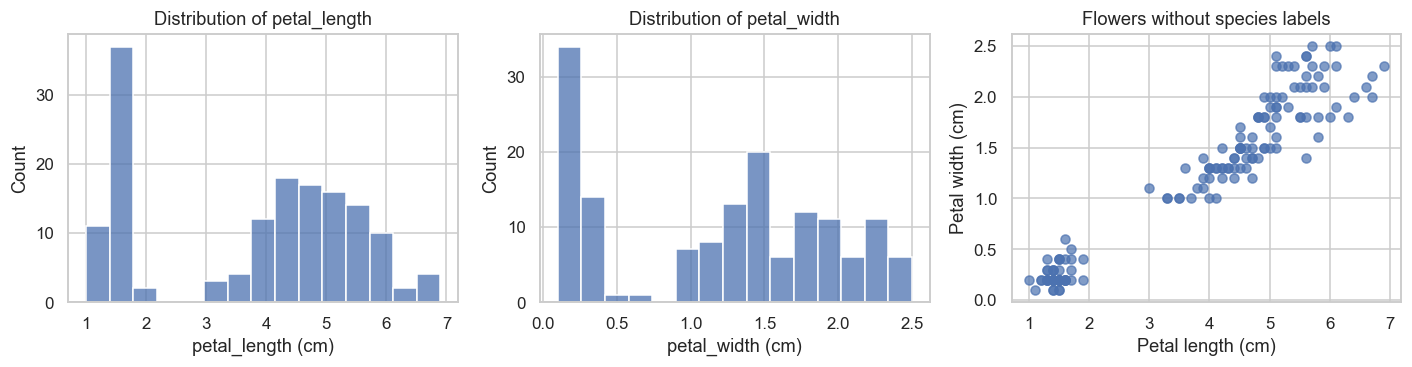

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, column in zip(axes[:2], FEATURES):
    sns.histplot(data=X, x=column, bins=15, ax=ax)
    ax.set(xlabel=f"{column} (cm)", title=f"Distribution of {column}")
axes[2].scatter(X["petal_length"], X["petal_width"], s=35, alpha=0.7)
axes[2].set(xlabel="Petal length (cm)", ylabel="Petal width (cm)", title="Flowers without species labels")
fig.tight_layout(); plt.show()


- Notice a clearly separated small-petal group and a more continuous larger-petal region. Visible geometry need not form one cluster per species.


## How K-means works
A **centroid** is the mean feature vector of a cluster. For K centroids, repeat:

1. **Initialize:** choose starting centroid locations.
2. **Assign:** send each observation to its nearest centroid.
3. **Update:** replace each centroid with the mean of its assigned observations.
4. **Repeat:** stop when the solution converges or the iteration limit is reached.

For two measurements, Euclidean distance is

$$d(x,\mu)=\sqrt{(x_1-\mu_1)^2+(x_2-\mu_2)^2}.$$

K-means minimizes **inertia**, also called within-cluster SSE:

$$J=\sum_{i=1}^{n}\lVert x_i-\mu_{c_i}\rVert_2^2.$$

- $x_i$: observation i; $c_i$: its assigned cluster; $\mu_{c_i}$: that cluster's centroid.
- K-means++ spreads initial centers using a distance-based strategy.
- Different starting points can lead to different local solutions. Multiple initializations help but do not guarantee the global optimum.
- K-means uses distances and averages; it does not use backpropagation, species labels, or classification cross-entropy.


### 7. Calculate one assignment and update by hand

- Use four small two-dimensional observations to make the computation visible.
- Compare squared distances, choose the nearest center, and calculate new means.


In [7]:
toy_points = np.array([[1., 1.], [1., 3.], [7., 7.], [9., 7.]])
toy_centers = np.array([[1., 1.], [7., 7.]])
squared_distances = ((toy_points[:, None, :] - toy_centers[None, :, :]) ** 2).sum(axis=2)
toy_labels = squared_distances.argmin(axis=1)
updated_centers = np.array([toy_points[toy_labels == k].mean(axis=0) for k in range(2)])
display(pd.DataFrame({"Point": toy_points.tolist(),
    "Squared distance to center 0": squared_distances[:, 0],
    "Squared distance to center 1": squared_distances[:, 1],
    "Assigned cluster": toy_labels}))
print("Updated centers:")
print(updated_centers)
print("SSE before update:", squared_distances.min(axis=1).sum())
print("SSE after update:", ((toy_points - updated_centers[toy_labels]) ** 2).sum())


,Point,Squared distance to center 0,Squared distance to center 1,Assigned cluster
0,"[1.0, 1.0]",0.0,72.0,0
1,"[1.0, 3.0]",4.0,52.0,0
2,"[7.0, 7.0]",72.0,0.0,1
3,"[9.0, 7.0]",100.0,4.0,1


Updated centers:
[[1. 2.]
 [8. 7.]]
SSE before update: 8.0
SSE after update: 4.0


- The new centers are [1, 2] and [8, 7]. Each mean lies at the center of its assigned pair, and SSE decreases from 8 to 4.


### 8. Standardize the features

- Standardization centers each feature at zero and divides it by its standard deviation.
- This gives length and width comparable influence by spread; it is a choice about distance, even when both are measured in centimeters.
- This lesson describes the observed dataset, so preprocessing is fitted on these observations. The reported internal scores are not held-out predictive performance.


In [8]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
display(pd.DataFrame({"Original mean (cm)": scaler.mean_,
    "Original standard deviation (cm)": scaler.scale_,
    "Scaled mean": X_scaled.mean(axis=0),
    "Scaled standard deviation": X_scaled.std(axis=0)}, index=FEATURES))


,Original mean (cm),Original standard deviation (cm),Scaled mean,Scaled standard deviation
petal_length,3.7580,1.7594,-4.2633e-16,1.0
petal_width,1.1993,0.7597,-4.7370e-16,1.0


- Save this fitted scaler for future inputs. Standardization does not restrict values to [0, 1]. For future-data evaluation, split first and fit preprocessing on training observations only.


## Choosing K: two simple diagnostics
- **Inertia:** smaller means observations are closer to their assigned centroids in the chosen feature space. It generally falls as K increases, so the smallest inertia alone is not a useful selection rule.
- **Elbow:** look for a bend after which increasing K produces only modest inertia reductions. The bend may be ambiguous.
- **Silhouette:** compares an observation's average distance within its cluster, $a(i)$, with its smallest average distance to another cluster, $b(i)$.

$$s(i)=\frac{b(i)-a(i)}{\max(a(i),b(i))}.$$

- Values near +1 suggest good separation, values near 0 suggest overlap, and negative values suggest a questionable assignment.
- scikit-learn assigns singleton clusters a silhouette of 0. Silhouette is undefined for a one-cluster partition.
- There is no universal score threshold proving that a partition is good. Neither diagnostic must reproduce biological species.


### 9. Compare candidate values of K

- Fit K=1 through K=8 using the same scaled observations.
- Leave silhouette undefined for K=1.
- Show the results in a compact table.


In [9]:
comparison_rows = []
for k in K_VALUES:
    candidate = make_model(k)
    labels = candidate.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels) if k >= 2 else np.nan
    comparison_rows.append({"K": k, "Inertia": candidate.inertia_, "Silhouette": score})
k_comparison = pd.DataFrame(comparison_rows)
display(k_comparison)


c:\Users\user\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\user\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\user\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\user\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\user\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(

,K,Inertia,Silhouette
0,1,300.0000,NaN
1,2,54.1688,0.7434
2,3,18.0270,0.6741
3,4,12.2834,0.5988
4,5,9.1521,0.5736
5,6,7.2827,0.5818
6,7,6.0112,0.5728
7,8,5.1309,0.5898


- Scores are comparable because all candidates use the same observations and scaling. The reference species labels remain unused.


### 10. Plot the elbow and silhouette curves

- Compare both curves instead of treating one score as a biological truth detector.
- Use axis labels that identify the distance representation.


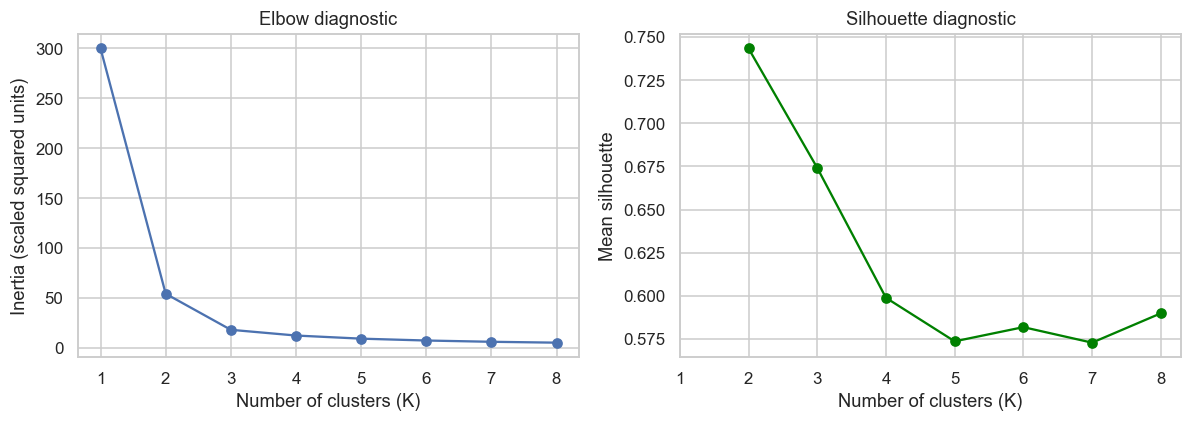

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(k_comparison["K"], k_comparison["Inertia"], "o-")
axes[0].set(xlabel="Number of clusters (K)", ylabel="Inertia (scaled squared units)", title="Elbow diagnostic")
valid_scores = k_comparison.dropna(subset=["Silhouette"])
axes[1].plot(valid_scores["K"], valid_scores["Silhouette"], "o-", color="green")
axes[1].set(xlabel="Number of clusters (K)", ylabel="Mean silhouette", title="Silhouette diagnostic")
for ax in axes:
    ax.set_xticks(list(K_VALUES))
fig.tight_layout(); plt.show()


- Iris can favor two geometric groups under silhouette even though the dataset contains three species. That disagreement is a useful lesson about clusters versus classes.


### 11. Select K and fit the main model

- Use the highest tested silhouette for the main model; ties favor the smaller K.
- Declare this rule before revealing species labels.
- Preserve the fitted model for all following inference and diagnostics.


In [11]:
ranked = valid_scores.sort_values(["Silhouette", "K"], ascending=[False, True])
selected_k = int(ranked.iloc[0]["K"])
model = make_model(selected_k)
cluster_labels = model.fit_predict(X_scaled)
assert len(np.unique(cluster_labels)) == selected_k
centers_raw = scaler.inverse_transform(model.cluster_centers_)
print("Selected K:", selected_k)
print("Iterations:", model.n_iter_, "of", MAX_ITER)
print("Inertia:", model.inertia_)
print("Mean silhouette:", silhouette_score(X_scaled, cluster_labels))
display(pd.DataFrame(centers_raw, columns=FEATURES).rename_axis("Cluster"))


c:\Users\user\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Selected K: 2
Iterations: 2 of 300
Inertia: 54.16878133149558
Mean silhouette: 0.743371950414545


,petal_length,petal_width
Cluster,,
0,4.906,1.676
1,1.462,0.246


- Cluster 0 and cluster 1 are arbitrary IDs. They are neither ordered measurements nor species names.


### 12. Visualize the selected clusters and centroids

- Plot the original measurements in centimeters.
- Inverse-transform centroids before placing them on raw-unit axes.
- Label the centroids clearly and use one color per cluster.


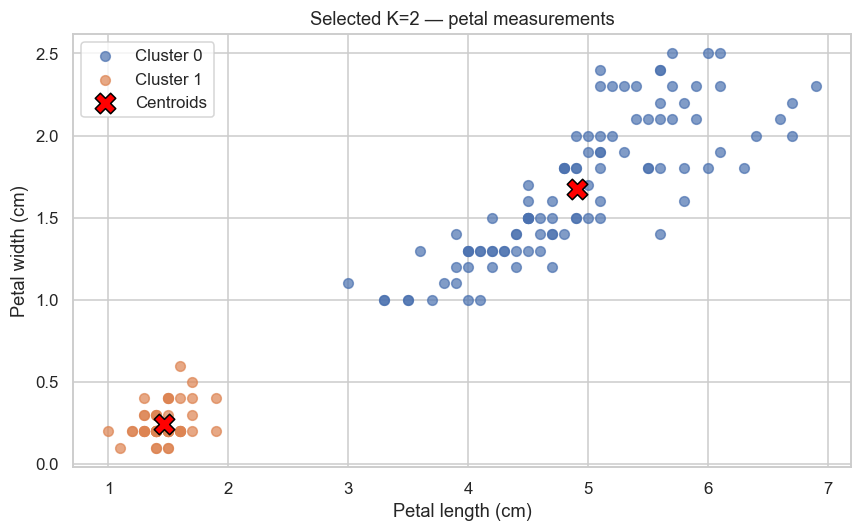

In [12]:
def plot_clusters(fitted_model, title, ax):
    labels = fitted_model.predict(X_scaled)
    centers = scaler.inverse_transform(fitted_model.cluster_centers_)
    for cluster in range(fitted_model.n_clusters):
        mask = labels == cluster
        ax.scatter(X.loc[mask, FEATURES[0]], X.loc[mask, FEATURES[1]],
                   s=40, alpha=0.7, label=f"Cluster {cluster}")
    ax.scatter(centers[:, 0], centers[:, 1], marker="X", s=180,
               c="red", edgecolors="black", label="Centroids", zorder=5)
    ax.set(xlabel="Petal length (cm)", ylabel="Petal width (cm)", title=title)
    ax.legend()

fig, ax = plt.subplots(figsize=(8, 5))
plot_clusters(model, f"Selected K={selected_k} — petal measurements", ax)
fig.tight_layout(); plt.show()


- The centroid is a mean measurement vector, not necessarily an actual observed flower. Overlapping points can occupy the same plotting location.


### 13. Compare K=2 and K=3 as a teaching exercise

- Fit two separate comparison models without overwriting the selected model.
- Discuss how a larger K subdivides the larger-petal region.
- This comparison is exploratory; it does not change the declared selection rule.


c:\Users\user\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\user\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


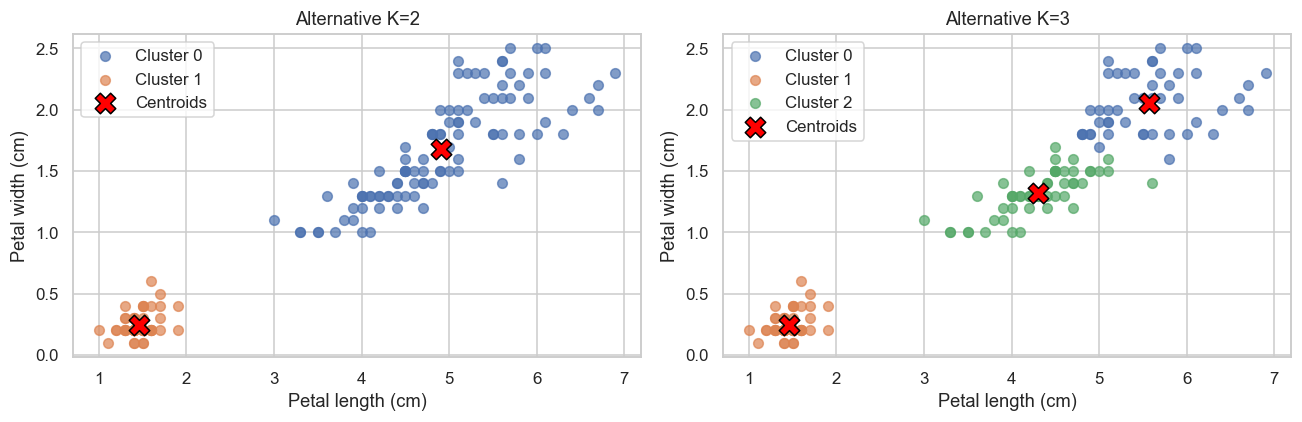

,K,Inertia,Silhouette
0,2,54.1688,0.7434
1,3,18.0270,0.6741


In [13]:
comparison_models = {k: make_model(k).fit(X_scaled) for k in [2, 3]}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (k, fitted) in zip(axes, comparison_models.items()):
    plot_clusters(fitted, f"Alternative K={k}", ax)
fig.tight_layout(); plt.show()
display(pd.DataFrame([{"K": k, "Inertia": fitted.inertia_,
    "Silhouette": silhouette_score(X_scaled, fitted.labels_)}
    for k, fitted in comparison_models.items()]))


- K=3 may be useful for discussion, but three known species do not prove that K-means should discover exactly three separated geometric groups.


### 14. Inspect cluster sizes, distances, and SSE

- Keep observations and their diagnostics together.
- Calculate distances in the same standardized space used for fitting.
- Verify that squared assigned-centroid distances sum to the model inertia.


In [14]:
distances = model.transform(X_scaled)
results = X.copy()
results["Cluster"] = cluster_labels
results["Distance to centroid (scaled)"] = distances[np.arange(len(X)), cluster_labels]
results["Silhouette"] = silhouette_samples(X_scaled, cluster_labels)
cluster_summary = results.groupby("Cluster").agg(
    Flowers=("Cluster", "size"), Mean_petal_length_cm=("petal_length", "mean"),
    Mean_petal_width_cm=("petal_width", "mean"), Mean_silhouette=("Silhouette", "mean"))
display(cluster_summary)
computed_sse = np.square(results["Distance to centroid (scaled)"]).sum()
np.testing.assert_allclose(computed_sse, model.inertia_, rtol=1e-7)
print("Verified SSE:", computed_sse)
display(results.head(10))


,Flowers,Mean_petal_length_cm,Mean_petal_width_cm,Mean_silhouette
Cluster,,,,
0,100,4.906,1.676,0.6526
1,50,1.462,0.246,0.9249


Verified SSE: 54.16878133149558


,petal_length,petal_width,Cluster,Distance to centroid (scaled),Silhouette
0,1.4,0.2,1,0.0701,0.9492
1,1.4,0.2,1,0.0701,0.9492
2,1.3,0.2,1,0.1102,0.9415
3,1.5,0.2,1,0.0643,0.9482
4,1.4,0.2,1,0.0701,0.9492
5,1.7,0.4,1,0.2437,0.8862
6,1.4,0.3,1,0.0793,0.9369
7,1.5,0.2,1,0.0643,0.9482
8,1.4,0.2,1,0.0701,0.9492
9,1.5,0.1,1,0.1934,0.9211


- A small distance describes proximity to a centroid. It is not a probability of correctness or a calibrated confidence score.


### 15. Inspect low-silhouette flowers

- Display the observations with the smallest silhouette values.
- Plot a sorted silhouette profile within each cluster.
- Mark the overall mean, while keeping negative values visible.


,petal_length,petal_width,Cluster,Distance to centroid (scaled),Silhouette
98,3.0,1.1,0,1.3223,0.0389
57,3.3,1.0,0,1.2748,0.0933
93,3.3,1.0,0,1.2748,0.0933
60,3.5,1.0,0,1.1960,0.1932
79,3.5,1.0,0,1.1960,0.1932
81,3.7,1.0,0,1.1232,0.2772
62,4.0,1.0,0,1.0281,0.3770
80,3.8,1.1,0,0.9849,0.3987


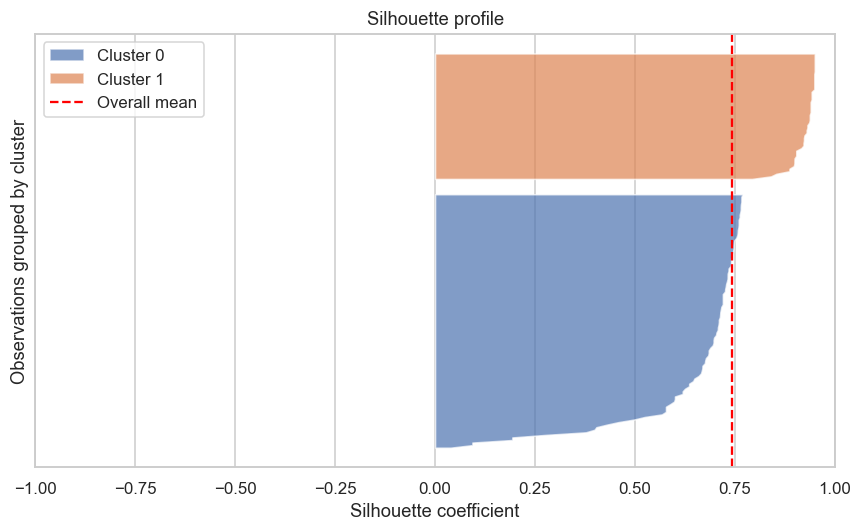

In [15]:
display(results.nsmallest(8, "Silhouette"))
fig, ax = plt.subplots(figsize=(8, 5))
y_lower = 5
for cluster in range(selected_k):
    values = np.sort(results.loc[results["Cluster"] == cluster, "Silhouette"].to_numpy())
    y_upper = y_lower + len(values)
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, values, alpha=0.7, label=f"Cluster {cluster}")
    y_lower = y_upper + 5
ax.axvline(results["Silhouette"].mean(), color="red", linestyle="--", label="Overall mean")
ax.set(xlim=(-1, 1), xlabel="Silhouette coefficient", ylabel="Observations grouped by cluster",
       title="Silhouette profile", yticks=[])
ax.legend(); fig.tight_layout(); plt.show()


- A low silhouette can reflect overlap or an unsuitable partition. It does not prove that the flower measurement or species label is wrong.


## Clusters are not species labels
- Species labels are now revealed only after K selection and fitting.
- Cluster numbers can be permuted without changing a partition. Comparing `cluster_id == species_code` is therefore invalid.
- A **contingency table** counts species in each predicted cluster and can be rectangular when group counts differ.
- **Adjusted Rand index (ARI)** compares partitions independently of their numeric label names. It is 1 for identical partitions, near 0 for chance-level agreement, and can be negative.
- Agreement here is a descriptive comparison on the fitted observations, not held-out classification accuracy.


### 16. Compare the frozen clusters with species

- Inspect species composition and ARI for the selected partition and the two comparison models.
- Do not use the results to claim the algorithm trained on species.
- Keep the selected model unchanged.


Predicted cluster,0,1
Actual species,,
setosa,0,50
versicolor,50,0
virginica,50,0


,Model,ARI with species
0,Selected K=2,0.5681
1,Exploratory K=2,0.5681
2,Exploratory K=3,0.8857


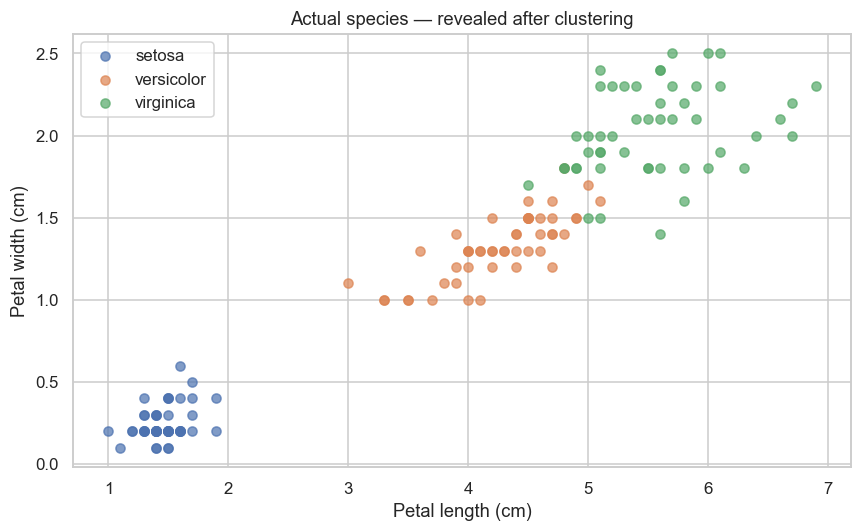

In [16]:
composition = pd.crosstab(species_reference.rename("Actual species"),
                          pd.Series(cluster_labels, index=X.index, name="Predicted cluster"))
display(composition)
reference_rows = [{"Model": f"Selected K={selected_k}",
    "ARI with species": adjusted_rand_score(species_reference, cluster_labels)}]
for k, fitted in comparison_models.items():
    reference_rows.append({"Model": f"Exploratory K={k}",
        "ARI with species": adjusted_rand_score(species_reference, fitted.labels_)})
display(pd.DataFrame(reference_rows))
fig, ax = plt.subplots(figsize=(8, 5))
for species in sorted(species_reference.unique()):
    mask = species_reference == species
    ax.scatter(X.loc[mask, FEATURES[0]], X.loc[mask, FEATURES[1]], alpha=0.7, label=species)
ax.set(xlabel="Petal length (cm)", ylabel="Petal width (cm)", title="Actual species — revealed after clustering")
ax.legend(); fig.tight_layout(); plt.show()


- A partition can score well on silhouette while merging species. Species agreement and geometric separation answer different questions.


### 17. Assign a new flower using the fitted scaler

- Supply raw measurements with exactly the same names and order.
- Transform with the fitted scaler, then predict the nearest existing centroid.
- Do not fit another scaler on the new observations.


In [18]:
new_flowers = pd.DataFrame({"petal_length": [1.5, 4.5, 5.8],
                            "petal_width": [0.2, 1.4, 2.1]})[FEATURES]

def assign_flowers(raw_measurements, fitted_scaler, fitted_model, feature_names):
    if list(raw_measurements.columns) != list(feature_names):
        raise ValueError(f"Use these columns in order: {feature_names}")
    values = raw_measurements.to_numpy(dtype=float)
    if not np.isfinite(values).all() or (values <= 0).any():
        raise ValueError("Provide finite, positive measurements in centimeters.")
    scaled = fitted_scaler.transform(raw_measurements)
    labels = fitted_model.predict(scaled)
    distances = fitted_model.transform(scaled)
    output = raw_measurements.copy()
    output["Assigned cluster"] = labels
    output["Distance to centroid (scaled)"] = distances[np.arange(len(values)), labels]
    return output

for column in FEATURES:
    if (~new_flowers[column].between(X[column].min(), X[column].max())).any():
        print(f"Caution: a new value is outside the observed range for {column}.")
new_assignments = assign_flowers(new_flowers, scaler, model, FEATURES)
display(new_assignments)


,petal_length,petal_width,Assigned cluster,Distance to centroid (scaled)
0,1.5,0.2,1,0.0643
1,4.5,1.4,0,0.4304
2,5.8,2.1,0,0.7548


- The result is a cluster ID, not an automatically learned species name. K-means assigns even an unfamiliar flower to an existing cluster.


### 18. Visualize the new flowers

- Overlay the new observations using a different marker.
- Keep the raw measurement units and original centroids.


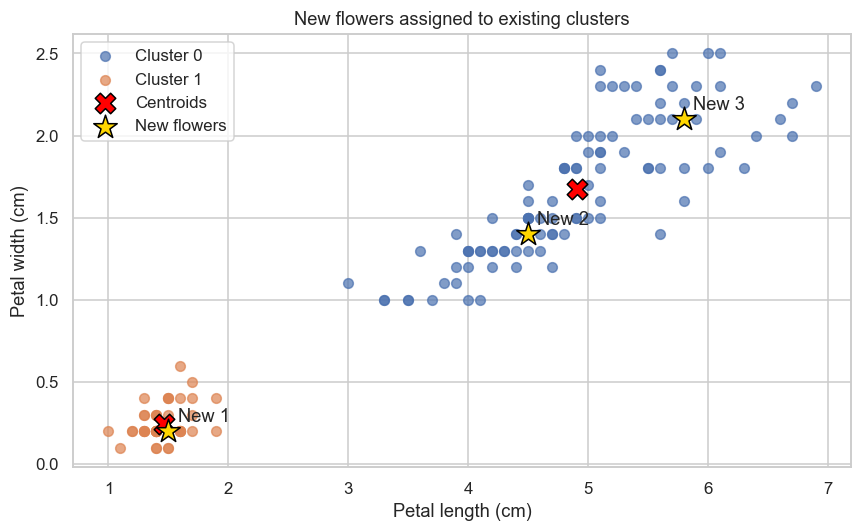

In [19]:
fig, ax = plt.subplots(figsize=(8, 5))
plot_clusters(model, "New flowers assigned to existing clusters", ax)
ax.scatter(new_flowers[FEATURES[0]], new_flowers[FEATURES[1]],
           marker="*", s=260, c="gold", edgecolors="black", label="New flowers", zorder=6)
for i, point in enumerate(new_flowers.to_numpy()):
    ax.annotate(f"New {i+1}", point, xytext=(6, 6), textcoords="offset points")
ax.legend(); fig.tight_layout(); plt.show()


- Predicting new inputs does not update the centroids. Call `fit` again only when intentionally retraining the clustering solution.


### 19. Save the model, scaler, and feature order

- Save preprocessing alongside the model so raw measurements can be processed consistently.
- Save the data source and settings in metadata for reproducibility.
- Load joblib files only from trusted sources because deserialization can execute code.


In [20]:
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump({"model": model, "scaler": scaler}, ARTIFACT_DIR / "iris_kmeans.joblib")
metadata = {"features": FEATURES, "units": "centimeters", "selected_k": selected_k,
    "selection_rule": "Highest silhouette among tested K values; smaller K wins ties",
    "source": data_source, "random_state": RANDOM_STATE, "n_init": N_INIT,
    "sklearn_version": sklearn.__version__, "analysis_scope": "Descriptive clustering of observed data"}
(ARTIFACT_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
results.to_csv(ARTIFACT_DIR / "flower_cluster_assignments.csv", index_label="Original row")
k_comparison.to_csv(ARTIFACT_DIR / "k_comparison.csv", index=False)
print("Saved artifacts to:", ARTIFACT_DIR.resolve())


Saved artifacts to: C:\Users\user\Documents\GitHub\AI\iris_kmeans_artifacts


- The fitted scaler preserves means and standard deviations; metadata preserves feature meaning and order. Rerunning this cell overwrites these lesson artifacts.


### 20. Reload and verify the assignments

- Load the saved model, scaler, and metadata.
- Check numerical agreement for distances as well as exact agreement for assignments.


In [21]:
loaded = joblib.load(ARTIFACT_DIR / "iris_kmeans.joblib")
loaded_metadata = json.loads((ARTIFACT_DIR / "metadata.json").read_text(encoding="utf-8"))
assert loaded_metadata["features"] == FEATURES
loaded_inputs = new_flowers[loaded_metadata["features"]]
loaded_assignments = assign_flowers(loaded_inputs, loaded["scaler"], loaded["model"],
                                   loaded_metadata["features"])
np.testing.assert_array_equal(loaded_assignments["Assigned cluster"], new_assignments["Assigned cluster"])
np.testing.assert_allclose(loaded_assignments["Distance to centroid (scaled)"],
                           new_assignments["Distance to centroid (scaled)"])
display(loaded_assignments)
print("Reloaded assignments and distances match the original results.")


,petal_length,petal_width,Assigned cluster,Distance to centroid (scaled)
0,1.5,0.2,1,0.0643
1,4.5,1.4,0,0.4304
2,5.8,2.1,0,0.7548


Reloaded assignments and distances match the original results.


- This verifies saved inference on the example inputs. It does not establish that the clusters will be useful for a different flower population.


## Optional extension: Use all four measurements
- Run this after understanding the two-feature lesson.
- Keep the same selected K so the comparison changes feature representation, rather than choosing K using species labels.
- Use a separate scaler and model; retain the main two-feature model for new-point prediction.
- Four-dimensional distances cannot be fully represented in one two-dimensional scatter plot. Do not interpret a two-feature slice as showing the complete geometry.


### 21. Fit a four-feature model at the same K

- Standardize each of the four measurements separately.
- Compare ARI between partitions and report each model’s own silhouette.
- Do not compare inertia across different feature dimensions as if it measured the same objective.


In [22]:
X_four = df[ALL_FEATURES].copy()
scaler_four = StandardScaler()
X_four_scaled = scaler_four.fit_transform(X_four)
model_four = make_model(selected_k).fit(X_four_scaled)
display(pd.DataFrame({
    "Representation": ["Two petal measurements", "All four measurements"],
    "K": [selected_k, selected_k],
    "Silhouette in its own feature space": [silhouette_score(X_scaled, cluster_labels),
        silhouette_score(X_four_scaled, model_four.labels_)]}))
print("ARI between the two partitions:", adjusted_rand_score(cluster_labels, model_four.labels_))


c:\Users\user\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,Representation,K,Silhouette in its own feature space
0,Two petal measurements,2,0.7434
1,All four measurements,2,0.5818


ARI between the two partitions: 1.0


- Adding features changes the distance geometry and can change assignments. More features do not automatically produce more useful clusters; silhouette values also depend on their representation.
